# 01 - Data Exploration

## Project: Retail Sales Forecasting

### Objectives
- Understand the dataset structure.
- Explore data types and statistical properties.
- Identify missing values and duplicates.
- Analyze sales distributions and patterns.
- Investigate relationships between features and sales.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported successfully!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully!
Pandas: 3.1.1
Scikit-learn: 1.9.1


## 1. Loading the datasets

In [4]:
# Define project paths
from pathlib import Path
ROOT_DIR = Path.cwd()

if ROOT_DIR.name == "notebooks":
    ROOT_DIR = ROOT_DIR.parent

DATA_DIR = ROOT_DIR / "data" / "raw"

# Load datasets
train = pd.read_csv(DATA_DIR / "train.csv")
store = pd.read_csv(DATA_DIR / "store.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

# Display confirmation
print("Datasets loaded successfully!")

C:\Users\mrymh\AppData\Local\Temp\ipykernel_18248\2826480446.py:11: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv(DATA_DIR / "train.csv")


Datasets loaded successfully!


In [5]:
print("TRAIN DATASET")
display(train.head())

print("STORE DATASET")
display(store.head())

print("TEST DATASET")
display(test.head())

TRAIN DATASET


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


STORE DATASET


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


TEST DATASET


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0


In [7]:
# shape returns (number_of_rows, number_of_columns)
print("Train shape:", train.shape)
print("Store shape:", store.shape)
print("Test shape:", test.shape)

Train shape: (1017209, 9)
Store shape: (1115, 10)
Test shape: (41088, 8)


In [8]:
train.info()
store.info()
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  str   
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(1), str(1)
memory usage: 69.8+ MB
<class 'pandas.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   str    
 2   Assortment          

In [9]:
# Check missing values in each dataset

print("Missing values in TRAIN:")
print(train.isnull().sum())

print("\nMissing values in STORE:")
print(store.isnull().sum())

print("\nMissing values in TEST:")
print(test.isnull().sum())

Missing values in TRAIN:
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

Missing values in STORE:
Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64

Missing values in TEST:
Id                0
Store             0
DayOfWeek         0
Date              0
Open             11
Promo             0
StateHoliday      0
SchoolHoliday     0
dtype: int64


In [12]:
#calculate the percentage of missing
def missing_values_report(df):
    missing = pd.DataFrame({
        'Missing Values': df.isnull().sum(),
        'Percentage (%)': (df.isnull().sum() / len(df)) * 100
    })

    return missing[missing['Missing Values'] > 0].sort_values(
        by='Percentage (%)',
        ascending=False
    )

print("TRAIN:")
display(missing_values_report(train))

print("STORE:")
display(missing_values_report(store))

print("TEST:")
display(missing_values_report(test))

TRAIN:


,Missing Values,Percentage (%)


STORE:


,Missing Values,Percentage (%)
Promo2SinceYear,544,48.789238
Promo2SinceWeek,544,48.789238
PromoInterval,544,48.789238
CompetitionOpenSinceMonth,354,31.748879
CompetitionOpenSinceYear,354,31.748879
CompetitionDistance,3,0.269058


TEST:


,Missing Values,Percentage (%)
Open,11,0.026772


In [13]:
#Check duplicate records
print("Train duplicates:", train.duplicated().sum())
print("Store duplicates:", store.duplicated().sum())
print("Test duplicates:", test.duplicated().sum())

Train duplicates: 0
Store duplicates: 0
Test duplicates: 0


In [14]:
#check unique identifier in the store dataset
print("Unique stores:", store['Store'].nunique())
print("Total store records:", len(store))

Unique stores: 1115
Total store records: 1115


In [15]:
# Convert Date columns to datetime

train['Date'] = pd.to_datetime(train['Date'])
test['Date'] = pd.to_datetime(test['Date'])

print("Training period:")
print(train['Date'].min(), "to", train['Date'].max())

print("\nTesting period:")
print(test['Date'].min(), "to", test['Date'].max())

Training period:
2013-01-01 00:00:00 to 2015-07-31 00:00:00

Testing period:
2015-08-01 00:00:00 to 2015-09-17 00:00:00


## 2. Missing Values Investigation

In [16]:
# Relationship between Promo2 and missing promotional information

print(pd.crosstab(
    store['Promo2'],
    store['Promo2SinceWeek'].isnull(),
    margins=True
))

Promo2SinceWeek  False  True   All
Promo2                            
0                    0   544   544
1                  571     0   571
All                571   544  1115


In [17]:
# Check missing competition opening dates

print(pd.crosstab(
    store['CompetitionOpenSinceYear'].isnull(),
    store['CompetitionOpenSinceMonth'].isnull(),
    margins=True
))

CompetitionOpenSinceMonth  False  True   All
CompetitionOpenSinceYear                    
False                        761     0   761
True                           0   354   354
All                          761   354  1115


In [18]:
store[store['CompetitionDistance'].isnull()]

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
290,291,d,a,NaN,NaN,NaN,0,NaN,NaN,NaN
621,622,a,c,NaN,NaN,NaN,0,NaN,NaN,NaN
878,879,d,a,NaN,NaN,NaN,1,5.0,2013.0,"Feb,May,Aug,Nov"


In [19]:
# Display records with missing Open values

missing_open = test[test['Open'].isnull()]

display(missing_open)

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
479,480,622,4,2015-09-17,NaN,1,0,0
1335,1336,622,3,2015-09-16,NaN,1,0,0
2191,2192,622,2,2015-09-15,NaN,1,0,0
3047,3048,622,1,2015-09-14,NaN,1,0,0
4759,4760,622,6,2015-09-12,NaN,0,0,0
5615,5616,622,5,2015-09-11,NaN,0,0,0
6471,6472,622,4,2015-09-10,NaN,0,0,0
7327,7328,622,3,2015-09-09,NaN,0,0,0
8183,8184,622,2,2015-09-08,NaN,0,0,0
9039,9040,622,1,2015-09-07,NaN,0,0,0


## 3. Target Variable Analysis

In [20]:
# Statistical summary of numerical columns

display(train[['Sales', 'Customers']].describe())

,Sales,Customers
count,1.017209e+06,1.017209e+06
mean,5.773819e+03,6.331459e+02
std,3.849926e+03,4.644117e+02
min,0.000000e+00,0.000000e+00
25%,3.727000e+03,4.050000e+02
50%,5.744000e+03,6.090000e+02
75%,7.856000e+03,8.370000e+02
max,4.155100e+04,7.388000e+03


In [21]:
# Check sales when stores are closed

print("Closed store records:", (train['Open'] == 0).sum())

print("Records with zero sales:", (train['Sales'] == 0).sum())

print("Open stores with zero sales:",
      ((train['Open'] == 1) & (train['Sales'] == 0)).sum())

Closed store records: 172817
Records with zero sales: 172871
Open stores with zero sales: 54


In [23]:
#check categorial features
categorical_columns = [
    'StoreType',
    'Assortment',
    'PromoInterval'
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(store[col].value_counts(dropna=False))


StoreType:
StoreType
a    602
d    348
c    148
b     17
Name: count, dtype: int64

Assortment:
Assortment
a    593
c    513
b      9
Name: count, dtype: int64

PromoInterval:
PromoInterval
NaN                 544
Jan,Apr,Jul,Oct     335
Feb,May,Aug,Nov     130
Mar,Jun,Sept,Dec    106
Name: count, dtype: int64


In [25]:
print("StateHoliday:")
print(train['StateHoliday'].value_counts(dropna=False))

print("\nSchoolHoliday:")
print(train['SchoolHoliday'].value_counts(dropna=False))

StateHoliday:
StateHoliday
0    855087
0    131072
a     20260
b      6690
c      4100
Name: count, dtype: int64

SchoolHoliday:
SchoolHoliday
0    835488
1    181721
Name: count, dtype: int64


### 3.1 Sales Distribution Analysis

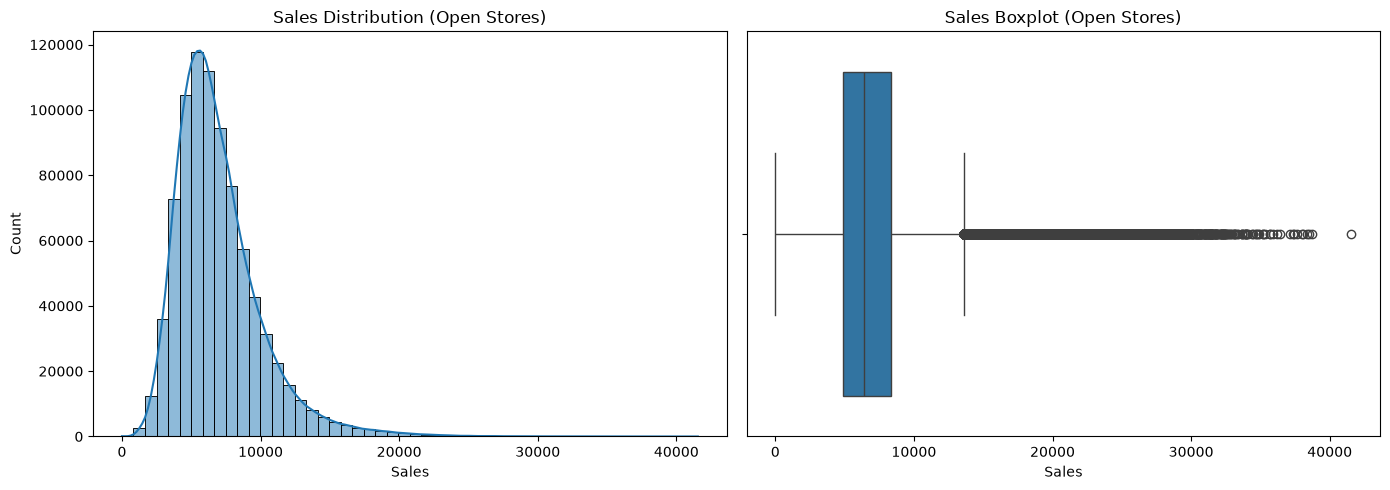

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Consider only open stores
open_stores = train[train['Open'] == 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sales distribution
sns.histplot(
    open_stores['Sales'],
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Sales Distribution (Open Stores)')
axes[0].set_xlabel('Sales')

# Boxplot
sns.boxplot(
    x=open_stores['Sales'],
    ax=axes[1]
)

axes[1].set_title('Sales Boxplot (Open Stores)')
axes[1].set_xlabel('Sales')

plt.tight_layout()
plt.show()